# Experiment 9: Named Entity Recognition for Resumes
**Mini-project:** Resume Analyzer Using Natural Language Processing (Group 28)

**Objective:** Implement NER on resumes with a pretrained spaCy model, a transformer (BERT) NER model and a rule-based EntityRuler, and evaluate them on Healthcare (biomedical) and Finance resumes.

Open in Colab: [Exp9_Named_Entity_Recognition.ipynb](https://colab.research.google.com/github/GnsShubham06/resume-analyzer-nlp/blob/main/notebooks/experiments/Exp9_Named_Entity_Recognition.ipynb) &nbsp;|&nbsp; Run with **Runtime → Run all**.
Data: 100 resumes (20 per domain); the screenshots in the report use five fictional (synthetic) resumes.

In [1]:
# ---- Setup: runs in Google Colab and locally --------------------------------
# In Colab this cell downloads the project repository (code + anonymised
# dataset) from GitHub and installs the packages Colab does not ship with.
import os, sys, subprocess, warnings
warnings.filterwarnings("ignore")
REPO = "https://github.com/GnsShubham06/resume-analyzer-nlp"
if "google.colab" in sys.modules:
    if not os.path.isdir("/content/resume-analyzer-nlp"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, "/content/resume-analyzer-nlp"], check=True)
    os.chdir("/content/resume-analyzer-nlp")
    extra = []
    if extra:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *extra], check=True)
else:  # local run from notebooks/experiments/
    for _ in range(3):
        if os.path.isfile("requirements.txt"):
            break
        os.chdir("..")
sys.path.insert(0, os.getcwd())

import nltk
for pkg in []:
    nltk.download(pkg, quiet=True)

import spacy
try:
    nlp = spacy.load("en_core_web_sm")
except OSError:  # model not installed yet (fresh Colab runtime)
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm", "-q"], check=True)
    import importlib, site
    importlib.invalidate_caches(); importlib.reload(site)
    import en_core_web_sm
    nlp = en_core_web_sm.load()

%config InlineBackend.figure_format = "retina"
import pandas as pd
pd.set_option("display.max_colwidth", 120)
df = pd.read_csv("data/resume_dataset.csv")
df["extracted_text"] = df["extracted_text"].fillna("")
print("Project folder:", os.path.basename(os.getcwd()), "| resumes:", len(df))

Project folder: resume-analyzer-nlp | resumes: 100


In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10})
ORDER = ["Engineering", "HR", "Finance", "Healthcare", "Agriculture"]
SAMPLE_IDS = {"Engineering": "ENG_06", "HR": "HR_06", "Finance": "FIN_07",
              "Healthcare": "HLT_04", "Agriculture": "AGR_02"}     # five fictional resumes
splits = pd.read_csv("data/processed/splits.csv")[["resume_id", "split"]]
df = df.merge(splits, on="resume_id")

import re
from spacy import displacy
from IPython.display import HTML
from transformers import pipeline
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
bert_ner = pipeline("token-classification", model="dslim/bert-base-NER", aggregation_strategy="simple")
print("models: spaCy", nlp.meta["name"], nlp.meta["version"], "| BERT: dslim/bert-base-NER (fine-tuned on CoNLL-2003)")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   9%|▊         | 17/199 [00:00<00:01, 138.01it/s]

Loading weights:  16%|█▌        | 31/199 [00:00<00:01, 98.54it/s] 

Loading weights:  21%|██        | 42/199 [00:00<00:01, 85.40it/s]

Loading weights:  26%|██▌       | 51/199 [00:00<00:02, 69.99it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 303.88it/s]

models: spaCy core_web_sm 3.8.0 | BERT: dslim/bert-base-NER (fine-tuned on CoNLL-2003)


## a. Pretrained NER on a Healthcare resume (spaCy and BERT)

In [3]:
text = df.set_index("resume_id").loc["HLT_04", "extracted_text"]
lines = [l for l in text.split("\n")[:12] if l.strip()][4:10]
snippet = "\n".join(lines)
doc = nlp(snippet)
labels = sorted({e.label_ for e in doc.ents})
display(HTML(displacy.render(doc, style="ent", jupyter=False,
                             options={"colors": {l: "#e6e6e6" for l in labels}})))
print("BERT NER:", [(snippet[e["start"]:e["end"]], e["entity_group"], round(float(e["score"]), 2))
                    for e in bert_ner(snippet)])

BERT NER: [("Kindwell Children's Hospital", 'LOC', 1.0), ('Chennai', 'LOC', 1.0)]


## b. Rule-based NER for resume entities (EntityRuler)
Pretrained models have no SKILL, DEGREE or JOB_TITLE labels, so we add an EntityRuler with patterns from our skill and job-title lexicons (`src/ner.py`) and a regex for date ranges.

In [4]:
from src.ner import rule_based_entities, rule_nlp
ruler = rule_nlp().get_pipe("entity_ruler")
print(f"EntityRuler patterns: {len(ruler.patterns)}")
fin_text = df.set_index("resume_id").loc["FIN_07", "cleaned_text"]
ents = rule_based_entities(fin_text)
by_label = {}
for e in sorted(ents, key=lambda e: e["start"]):
    by_label.setdefault(e["label"], [])
    if e["text"].lower() not in {x.lower() for x in by_label[e["label"]]}:
        by_label[e["label"]].append(e["text"])
display(pd.DataFrame([(k, len(v), ", ".join(v[:6]) + (" ..." if len(v) > 6 else "")) for k, v in by_label.items()],
                     columns=["label", "found", "entities in the Finance resume FIN_07"]))

EntityRuler patterns: 324


,label,found,entities in the Finance resume FIN_07
0,JOB_TITLE,2,"Finance Manager, Junior Accountant"
1,SKILL,17,"financial planning, month-end close, variance analysis, audit, Cost accounting, Accounts payable ..."
2,DEGREE,2,"MS, BBA"
3,EXPERIENCE_DATES,2,"Dec 2024 - Present, Jan 2022 - Dec 2024"


## c. Evaluation
Gold labels come from the experience header lines of the 82 fictional resumes, which have the fixed form *Job title, Organisation, City* followed by a date line. We score exact-match precision, recall and F1 for ORG, LOC and JOB_TITLE.

In [5]:
DATE = re.compile(r"^(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)[a-z]* \d{4} - ")
gold = []
for _, r in df[df.source_type == "synthetic"].iterrows():
    ls = [l.strip() for l in r.extracted_text.split("\n")]
    for l, nxt in zip(ls, ls[1:]):
        if DATE.match(nxt) and l.count(", ") == 2:
            title, org, city = l.split(", ")
            gold.append({"resume_id": r.resume_id, "domain": r.category, "line": l,
                         "JOB_TITLE": title, "ORG": org, "LOC": city})
gold = pd.DataFrame(gold)
print(len(gold), "gold lines;", gold.domain.value_counts().to_dict())
display(gold.head(3))

def predict(line):
    out = {"spaCy (en_core_web_sm)": set(), "BERT (dslim/bert-base-NER)": set(), "Rules (EntityRuler)": set()}
    for e in nlp(line).ents:
        if e.label_ in ("ORG", "GPE", "LOC"):
            out["spaCy (en_core_web_sm)"].add(("ORG" if e.label_ == "ORG" else "LOC", e.text))
    for e in bert_ner(line):
        if e["entity_group"] in ("ORG", "LOC"):
            out["BERT (dslim/bert-base-NER)"].add((e["entity_group"], line[e["start"]:e["end"]]))
    for e in rule_based_entities(line):
        if e["label"] == "JOB_TITLE":
            out["Rules (EntityRuler)"].add(("JOB_TITLE", e["text"]))
    return out
preds = [predict(l) for l in gold.line]

227 gold lines; {'Agriculture': 54, 'Finance': 47, 'Engineering': 45, 'Healthcare': 41, 'HR': 40}


,resume_id,domain,line,JOB_TITLE,ORG,LOC
0,AGR_02,Agriculture,"Seed Production Manager, Greenfurrow Seeds Pvt Ltd, Indore",Seed Production Manager,Greenfurrow Seeds Pvt Ltd,Indore
1,AGR_02,Agriculture,"Junior Field Officer, Monsoon Micro-Irrigation Systems, Mumbai",Junior Field Officer,Monsoon Micro-Irrigation Systems,Mumbai
2,AGR_03,Agriculture,"Crop Research Assistant, Golden Sheaf Farmer Producer Company, Pune",Crop Research Assistant,Golden Sheaf Farmer Producer Company,Pune


In [6]:
def score(system, label, mask):
    tp = n_pred = n_gold = 0
    for (_, g), p in zip(gold[mask].iterrows(), [preds[i] for i in np.where(mask)[0]]):
        ps = {t for lab, t in p[system] if lab == label}
        n_pred += len(ps); n_gold += 1; tp += g[label] in ps
    P = tp / n_pred if n_pred else 0.0; R = tp / n_gold
    return P, R, 2 * P * R / (P + R) if P + R else 0.0
rows = []
for system, labels in [("spaCy (en_core_web_sm)", ["ORG", "LOC"]), ("BERT (dslim/bert-base-NER)", ["ORG", "LOC"]),
                       ("Rules (EntityRuler)", ["JOB_TITLE"])]:
    for label in labels:
        for dom, mask in [("Healthcare", gold.domain.eq("Healthcare").to_numpy()),
                          ("Finance", gold.domain.eq("Finance").to_numpy()), ("all 5 domains", np.ones(len(gold), bool))]:
            P, R, F = score(system, label, mask)
            rows.append((system, label, dom, P, R, F))
res = pd.DataFrame(rows, columns=["system", "entity", "resumes", "precision", "recall", "F1"]).round(2)
display(res.pivot_table(index=["system", "entity"], columns="resumes", values="F1", sort=False)
           [["Healthcare", "Finance", "all 5 domains"]])

resumes                               Healthcare  Finance  all 5 domains
system                     entity                                       
spaCy (en_core_web_sm)     ORG              0.77     0.57           0.62
                           LOC              0.42     0.23           0.30
BERT (dslim/bert-base-NER) ORG              0.45     0.77           0.68
                           LOC              0.51     0.84           0.74
Rules (EntityRuler)        JOB_TITLE        0.54     0.48           0.42

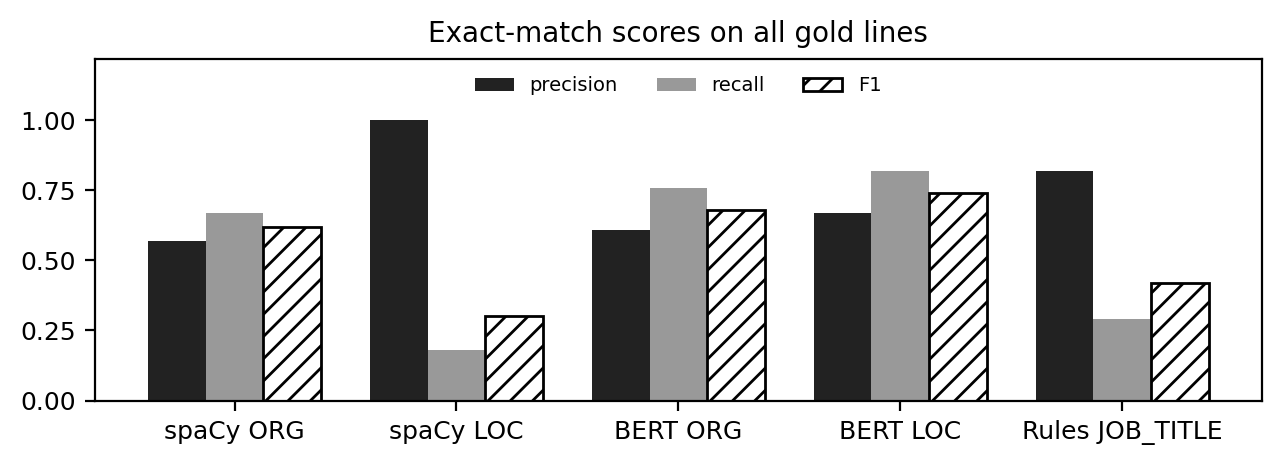

examples where spaCy missed the city: [('Seed Production Manager, Greenfurrow Seeds Pvt Ltd, Indore', []), ('Crop Research Assistant, Golden Sheaf Farmer Producer Company, Pune', []), ('Agronomist, Harvestline Agri Services, Coimbatore', [])]


In [7]:
allr = res[res.resumes == "all 5 domains"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(6.4, 2.4))
names = allr.system.str.split(" ").str[0] + " " + allr.entity
x = np.arange(len(allr))
for k, (m, style) in enumerate([("precision", dict(color="#222222")),
                                ("recall", dict(color="#999999")),
                                ("F1", dict(color="white", edgecolor="black", hatch="///"))]):
    ax.bar(x + (k - 1) * 0.26, allr[m], 0.26, label=m, **style)
ax.set_xticks(x, names); ax.set_ylim(0, 1.22); ax.legend(fontsize=7, ncol=3, loc="upper center", frameon=False)
ax.set_title("Exact-match scores on all gold lines"); plt.tight_layout(); plt.show()
errs = [(g.line, sorted(t for lab, t in p["spaCy (en_core_web_sm)"] if lab == "LOC"))
        for (_, g), p in zip(gold.iterrows(), preds) if g.LOC not in {t for lab, t in p["spaCy (en_core_web_sm)"] if lab == "LOC"}]
print("examples where spaCy missed the city:", errs[:3])